# Example 1: a thermal XXZ spin chain in the THz regime

A ring of six spin-½ moments with XXZ exchange in a static field is a small many-body system with a real thermal state. At 4 K several magnon-number sectors are populated, so the response is a sum over pathways launched from different sectors. In this notebook you will:

- build the many-body Hamiltonian with QuTiP (`qt.tensor` of single-spin operators);
- cut it into magnon-number sectors, the form the sparse solver expects;
- start from the canonical density matrix at $T=4$ K instead of a pure ground state;
- compute the one-magnon THz response and the third-order rephasing response with all eight sequences that the thermal state activates, including the bimagnon excited-state absorption;
- locate the bimagnon by total momentum, where its binding energy is defined;
- let the sparse backend solve its shifted systems exactly, since the closed generator is diagonal in the eigenbasis.

Convergence with the magnon cutoff and the dense–sparse comparison are kept out of this notebook; they are in `analysis/example1_analysis.ipynb`.

Natural units: $\hbar=1$. Energies in meV, field in tesla, temperature in kelvin, $\mu_B=0.0578838$ meV/T, $k_B=0.0861733$ meV/K.

## 0. Imports

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import qutip as qt

from qudpy_fdgf import (
    ExcitationSectorModel,
    FrequencyPathway,
    PropagationInterval,
    SpectroscopyPlotter,
    SpectroscopyProtocol,
    SpectroscopySolver,
    ThermodynamicContext,
    pathways_from_signature,
    standard_nq_protocol,
)

## 1. Physical model

The Hamiltonian is a periodic XXZ chain in a longitudinal field $B_0$,

$$
H=\sum_j\Big[J_{xy}\big(S^x_jS^x_{j+1}+S^y_jS^y_{j+1}\big)+J_z\,S^z_jS^z_{j+1}\Big]-g\mu_BB_0\sum_jS^z_j ,
$$

measured from the energy of the fully polarized state $|\!\uparrow\cdots\uparrow\rangle$. A **magnon** is one flipped spin, so the magnon number is $N=\sum_j(\tfrac12-S^z_j)$. The Hamiltonian conserves $N$.

The parameters are generic (an easy-axis ferromagnetic chain, not a fit to one compound). With $J_z<0$ two neighbouring magnons attract, which can produce a bound bimagnon state.

The THz magnetic field is uniform over the chain and flips one spin. Its excitation-raising part is

$$M^-=\frac1{\sqrt L}\sum_jS^-_j ,$$

which raises $N$ by one and, being uniform, conserves total momentum.

In [2]:
n_sites = 6
J_xy = -0.30           # meV, transverse exchange
J_z = -0.55            # meV, longitudinal exchange (also the magnon attraction)
g_factor = 2.10
B_0 = 7.1773           # tesla; puts the bright one-magnon state near 1.12 meV
temperature = 4.0      # kelvin
eta = 0.03             # meV, resolvent broadening

MU_B = 0.0578838       # meV / T
K_B = 0.08617333262    # meV / K


def site(op, j):
    """Operator `op` acting on spin j, identity on the others."""
    return qt.tensor([op if k == j else qt.qeye(2) for k in range(n_sites)])


Sx = [site(qt.sigmax() / 2, j) for j in range(n_sites)]
Sy = [site(qt.sigmay() / 2, j) for j in range(n_sites)]
Sz = [site(qt.sigmaz() / 2, j) for j in range(n_sites)]
S_minus = [site(qt.sigmam(), j) for j in range(n_sites)]   # flips |up> to |down>: creates a magnon

H = 0
for j in range(n_sites):
    k = (j + 1) % n_sites       # periodic boundary conditions
    H += J_xy * (Sx[j] * Sx[k] + Sy[j] * Sy[k]) + J_z * Sz[j] * Sz[k] - g_factor * MU_B * B_0 * Sz[j]

all_up = qt.tensor([qt.basis(2, 0)] * n_sites)
H = H - qt.expect(H, all_up)                      # energies relative to the polarized state

N_op = sum(0.5 - Sz[j] for j in range(n_sites))   # magnon number
M_minus = sum(S_minus) / np.sqrt(n_sites)         # uniform THz excitation operator

print(f"Hilbert space dimension: {H.shape[0]} = 2^{n_sites}")

Hilbert space dimension: 64 = 2^6


## 2. Magnon-number sectors

Because $H$ conserves $N$, it is block diagonal. `ExcitationSectorModel` takes the blocks $H_N$ and the rectangular blocks $M_{N+1,N}$ of the raising operator, and never builds the full matrix. We read $N$ off the diagonal of `N_op` and slice with it.

We keep $N\le N_{\max}=4$. A third-order pathway starting in sector $N$ can reach $N+2$, so $N_{\max}=4$ closes every pathway that starts in the thermally relevant sectors $N=0,1,2$ (see the analysis notebook for the truncation error).

In [3]:
max_magnons = 4

magnons = np.rint(N_op.diag().real).astype(int)            # N for each basis state
members = {N: np.flatnonzero(magnons == N) for N in range(max_magnons + 1)}

H_full, M_full = H.full(), M_minus.full()
hamiltonians = {N: H_full[np.ix_(idx, idx)] for N, idx in members.items()}
raising_blocks = {
    (N + 1, N): M_full[np.ix_(members[N + 1], members[N])] for N in range(max_magnons)
}

model = ExcitationSectorModel(
    hamiltonians, raising_blocks, initial_sector=0, boltzmann_constant=K_B
)
print("sector dimensions:", {N: model.dimension(N) for N in model.sectors()})

sector dimensions: {0: 1, 1: 6, 2: 15, 3: 20, 4: 15}


### Check: one-magnon dispersion

In the one-magnon sector the exact energies are $\omega(k)=g\mu_BB_0-J_z+J_{xy}\cos k$. The bright state of a uniform probe is $k=0$, at $g\mu_BB_0-J_z+J_{xy}$. The two-magnon sector contains the (attractive) bimagnon; its binding energy is defined below, at fixed total momentum.

In [4]:
k_points = 2 * np.pi * np.arange(n_sites) / n_sites
dispersion = g_factor * MU_B * B_0 - J_z + J_xy * np.cos(k_points)
one_magnon = np.linalg.eigvalsh(hamiltonians[1])
two_magnon = np.linalg.eigvalsh(hamiltonians[2])
bright_energy = g_factor * MU_B * B_0 - J_z + J_xy

print(f"max |E_numerical - E_analytical| (one magnon) = {np.abs(one_magnon - np.sort(dispersion)).max():.1e} meV")
print(f"bright k=0 energy: {bright_energy:.4f} meV")
print(f"two-magnon band: {two_magnon.min():.4f} to {two_magnon.max():.4f} meV")
assert np.allclose(one_magnon, np.sort(dispersion), atol=1e-12)

max |E_numerical - E_analytical| (one magnon) = 4.4e-16 meV
bright k=0 energy: 1.1224 meV
two-magnon band: 2.1108 to 3.3155 meV


### Check: the bimagnon at total momentum $K=0$

The uniform probe creates the bright magnon, which has $K=0$, and the transitions that follow stay in the sector of the same total momentum, so the bound state of interest is the lowest level of the two-magnon sector with $K=0$. Two independent magnons at the bottom of the one-magnon band, $2\omega(0)$, are not a reference for it: two magnons cannot occupy the same site, and the state with both at $k=0$ does not exist. A binding energy is the distance between the bound level and the lowest scattering level of the *same* sector. A ring of six sites has few levels of the continuum: two at $K=0$.

We project the two-magnon Hamiltonian on $K=0$ with the translation of the ring by one site, and read the probability $P_{nn}=\langle\sum_jn_jn_{j+1}\rangle$ that two magnons are neighbours. Uncorrelated magnons have $P_{nn}=L/\binom L2=0.4$.

In [5]:
dimension = 2**n_sites


def translated(index):
    # basis state of the ring translated by one site (site 0 is the most significant bit)
    bits = [(index >> (n_sites - 1 - j)) & 1 for j in range(n_sites)]
    bits = bits[-1:] + bits[:-1]
    return sum(bit << (n_sites - 1 - j) for j, bit in enumerate(bits))


translation = np.zeros((dimension, dimension))
for index in range(dimension):
    translation[translated(index), index] = 1.0
assert np.allclose(translation @ H.full(), H.full() @ translation)         # H is translation invariant

two = members[2]
H_two = H_full[np.ix_(two, two)]
T_two = translation[np.ix_(two, two)]
neighbours = sum((0.5 - Sz[j]) * (0.5 - Sz[(j + 1) % n_sites]) for j in range(n_sites)).full()[np.ix_(two, two)]

projector = sum(np.linalg.matrix_power(T_two, m) for m in range(n_sites)) / n_sites       # projector on K = 0
weights_K, vectors_K = np.linalg.eigh(projector)
basis_K0 = vectors_K[:, weights_K > 0.5]
levels_K0, states_K0 = np.linalg.eigh(basis_K0.T @ H_two @ basis_K0)
P_nn = [np.real(states_K0[:, i] @ basis_K0.T @ neighbours @ basis_K0 @ states_K0[:, i]) for i in range(levels_K0.size)]

print("K = 0 levels (meV):", np.round(levels_K0, 4), "  P_nn:", np.round(P_nn, 3))
free_pair = 2 * (g_factor * MU_B * B_0 - J_z + J_xy * np.cos(2 * np.pi / n_sites))      # 2 omega(q) of the first allowed pair
print(f"binding energy against the first scattering level of K = 0: {levels_K0[1] - levels_K0[0]:.4f} meV")
print(f"against the free pair 2 omega(2 pi / L): {free_pair - levels_K0[0]:.4f} meV")
print(f"the shift against 2 omega(0), {levels_K0[0] - 2 * bright_energy:+.4f} meV, is the displacement of the ESA line from the bright line")
assert abs(levels_K0[0] - two_magnon.min()) < 1e-12 and P_nn[0] > 0.4 > P_nn[1]

K = 0 levels (meV): [2.1108 2.5583 3.3155]   P_nn: [0.666 0.289 0.045]
binding energy against the first scattering level of K = 0: 0.4475 meV
against the free pair 2 omega(2 pi / L): 0.4341 meV
the shift against 2 omega(0), -0.1341 meV, is the displacement of the ESA line from the bright line


## 3. Thermal initial state

At 4 K the density matrix is $\rho_\beta=e^{-H/k_BT}/Z$, spread over several sectors. We pass `ThermodynamicContext(temperature=4.0)` to the solver, which asks the model for $\rho_\beta$. Here QuTiP gives the exact weights $P_N$ of the full six-site chain for comparison.

In [6]:
rho_beta = (-H / (K_B * temperature)).expm()
rho_beta = rho_beta / rho_beta.tr()
sector_weight = np.array([np.real((rho_beta * qt.Qobj(np.diag(magnons == N).astype(float),
                                                      dims=H.dims)).tr()) for N in range(n_sites + 1)])

for N, weight in enumerate(sector_weight):
    print(f"P(N={N}) = {weight:.6f}" + ("   <- not kept" if N > max_magnons else ""))
print(f"weight beyond N_max = {sector_weight[max_magnons + 1:].sum():.1e}")

P(N=0) = 0.885331
P(N=1) = 0.102734
P(N=2) = 0.010908
P(N=3) = 0.000955
P(N=4) = 0.000069
P(N=5) = 0.000004   <- not kept
P(N=6) = 0.000000   <- not kept
weight beyond N_max = 4.3e-06


At 4 K about 11 % of the population is in $N\ge1$, so a pure-ground-state calculation would miss hot-band contributions. Only $\sim10^{-5}$ lies beyond the retained sectors.

## 4. Solver

The `sparse_sector` backend never builds the Liouville matrix. It applies the generator block by block and solves each resolvent equation $[(\eta-i\omega)\mathbb 1-\mathcal L]x=b$. Here the model is closed (no collapse channels) and given in its eigenbasis, so the generator is diagonal and the backend solves each shifted system by a division, a sum over states (`diagonal_solve=True`, the default): the solution is exact and costs no iteration. With `diagonal_solve=False` the same systems are solved by GMRES, and the diagonal preconditioner (`preconditioner="auto"`) still makes every solve take one iteration; without a preconditioner the thermal state needs hundreds of iterations per solve (iteration counts in `analysis/example1_analysis.ipynb`, scaling with chain length in `benchmarks/`).

In [7]:
thermal_context = ThermodynamicContext(temperature=temperature)

solver = SpectroscopySolver(backend="sparse_sector", eta=eta)
solver.feed_model(model, context=thermal_context)

# Same model, pure ground state, for comparison
solver_pure = SpectroscopySolver(backend="sparse_sector", eta=eta)
solver_pure.feed_model(model)

print(solver.summary()["backend"], solver.summary()["sector_dimensions"])

sparse_sector {0: 1, 1: 6, 2: 15, 3: 20, 4: 15}


## 5. Linear THz response

One interaction `Ku` creates the coherence $|1\text{ magnon}\rangle\langle G|$. A uniform probe selects the $k=0$ magnon, so the pure-ground-state response peaks at the bright energy. At 4 K the thermally populated sectors add momentum-compatible hot bands ($N\to N+1$ transitions).

A protocol with one frequency interval and a single pathway is enough.

pure-state peak at 1.117 meV (expected 1.122 meV)


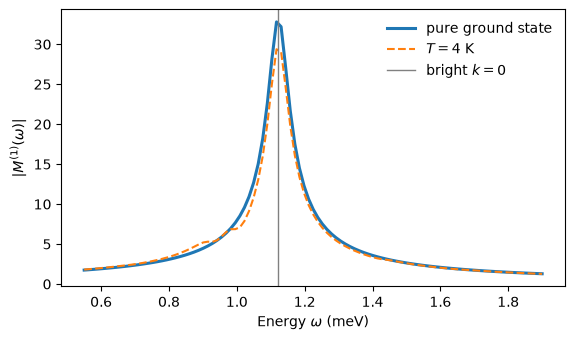

In [8]:
linear_pathway = FrequencyPathway(name="linear", interactions=("Ku",), component="linear")
linear_protocol = SpectroscopyProtocol(
    intervals=(PropagationInterval("omega", "frequency", coherence_order=1),), name="linear"
)

omega = np.linspace(0.55, 1.90, 101)


def linear_response(sol):
    return np.array(
        [sol.calc_pathway(linear_pathway, linear_protocol, {"omega": w}).value for w in omega]
    )


linear_pure = linear_response(solver_pure)
linear_thermal = linear_response(solver)

peak = omega[np.argmax(np.abs(linear_pure))]
print(f"pure-state peak at {peak:.3f} meV (expected {bright_energy:.3f} meV)")
assert abs(peak - bright_energy) < 2 * (omega[1] - omega[0])

linear_figure, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(omega, np.abs(linear_pure), lw=2.2, label="pure ground state")
ax.plot(omega, np.abs(linear_thermal), "--", label=f"$T={temperature:.0f}$ K")
ax.axvline(bright_energy, color="0.5", lw=1, label=r"bright $k=0$")
ax.set_xlabel(r"Energy $\omega$ (meV)")
ax.set_ylabel(r"$|M^{(1)}(\omega)|$")
ax.legend(frameon=False)
plt.show()

## 6. Third-order rephasing response: the eight sequences

A rephasing sequence has three interactions with the coherence orders $q=(-1,0,+1)$: the first lowers $q$ by one ($B_u$ or $K_d$), the other two raise it ($K_u$ or $B_d$). That makes $2\times2\times2=8$ sequences, and `pathways_from_signature("-++")` enumerates them, so that none is left out by hand. For the pure ground state three are non-zero,

$$R_{\rm GSB}=(B_u,B_d,K_u),\qquad R_{\rm SE}=(B_u,K_u,B_d),\qquad R_{\rm ESA}=(B_u,K_u,K_u);$$

at 4 K the thermally populated sectors activate the five others, which start with $K_d$ or end with two $B_d$. The labels GSB, SE and ESA name *topologies*, not only processes starting in the ground state: the same sequences act on every populated diagonal block of $\rho_\beta$. $R_{\rm ESA}$ goes to the two-magnon sector and leaves a $|2\text{ mag}\rangle\langle1\text{ mag}|$ coherence, which is where the bimagnon appears.

The waiting time is $t_2=0$. The grid is $60\times60$ points, $\Delta\omega\approx0.017$ meV.

In [9]:
pathways = pathways_from_signature("-++", component="rephasing")      # the eight sequences
print("sequences:", [p.name for p in pathways])
protocol = standard_nq_protocol(
    order=1, nq_interval=1, detection_interval=3, n_interactions=3,
    nq_axis="omega_1q", detection_axis="omega_emit",
)

omega_1q = np.linspace(-1.55, -0.55, 60)
omega_emit = np.linspace(0.55, 1.55, 60)

start = time.perf_counter()
result = solver.generate_spectrum(
    protocol,
    axes={"omega_1q": omega_1q, "omega_emit": omega_emit},
    fixed_coordinates={"t2": 0.0},
    pathways=pathways,
)
print(f"2D scan, eight sequences: {time.perf_counter() - start:.2f} s")

gsb, se, esa = (result.pathways[name] for name in ("Bu-Bd-Ku", "Bu-Ku-Bd", "Bu-Ku-Ku"))
rephasing = result.components["rephasing"]          # the sum of the eight sequences

sequences: ['Kd-Ku-Ku', 'Kd-Ku-Bd', 'Kd-Bd-Ku', 'Kd-Bd-Bd', 'Bu-Ku-Ku', 'Bu-Ku-Bd', 'Bu-Bd-Ku', 'Bu-Bd-Bd']


2D scan, eight sequences: 0.13 s


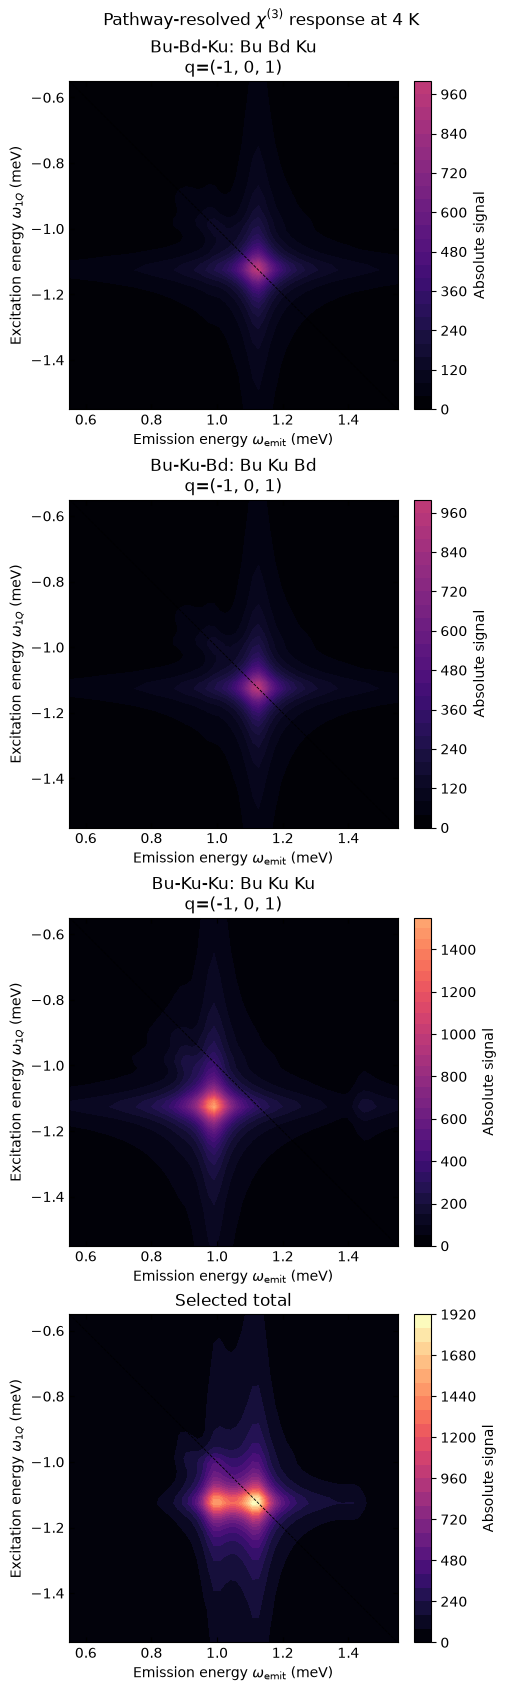

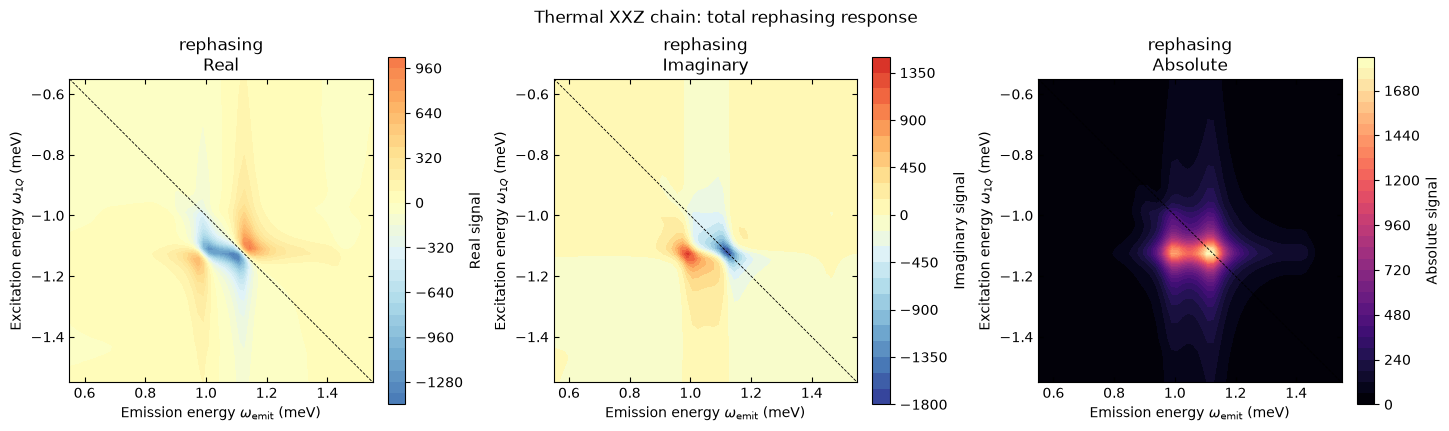

In [10]:
plotter = SpectroscopyPlotter(detection_phase=0.0)
axis_labels = (
    r"Emission energy $\omega_{\mathrm{emit}}$ (meV)",
    r"Excitation energy $\omega_{1Q}$ (meV)",
)

pathway_figure = plotter.plot_spectrum_result(
    result,
    params={
        "source": "pathways", "names": ["Bu-Bd-Ku", "Bu-Ku-Bd", "Bu-Ku-Ku"], "view": "abs",
        "normalization": "global", "labels": axis_labels, "diagonals": "auto",
        "title": r"Pathway-resolved $\chi^{(3)}$ response at 4 K",
        "style": {"abs_cmap": "magma", "levels": 30, "contour_lines": False},
    },
)
total_figure = plotter.plot_spectrum_result(
    result,
    params={
        "source": "components", "names": ["rephasing"], "view": "all",
        "normalization": "row", "labels": axis_labels, "diagonals": "auto",
        "title": r"Thermal XXZ chain: total rephasing response",
        "style": {"cmap": "RdYlBu_r", "abs_cmap": "magma", "levels": 30, "contour_lines": False},
    },
)

GSB and SE sit on the bright one-magnon resonance, $(\omega_{1Q},\omega_{\rm emit})\approx(-1.12,+1.12)$ meV. ESA starts from the same excitation energy but is emitted at $E_{\rm bimagnon}-E_{\rm bright}\approx0.99$ meV, $0.134$ meV below the bright line ($2\omega(0)-E_{\rm bimagnon}$, Section 2): an observable splitting, which the interaction $J_z$ produces, and not the binding energy of the bimagnon (0.447 meV at $K=0$). The total map therefore shows two peaks along $\omega_{1Q}\approx-1.12$ meV. The five thermal-only sequences add a hot-band contribution of a few per cent of the maximum.

## 7. Verification

Four checks that do not depend on how the map looks:
- the total is the sum of its sequences;
- the strongest feature lies at the bright magnon resonance;
- the ESA peak is emitted at $E_{\rm bimagnon}-E_{\rm bright}$, which requires the two-magnon sector;
- for the pure ground state only the three sequences GSB, SE and ESA are non-zero, as the sequences that start with $K_d$ or end with two $B_d$ need a populated sector $N\geq1$.

In [11]:
sum_residual = np.max(np.abs(rephasing - sum(result.pathways.values())))
i, j = np.unravel_index(np.argmax(np.abs(rephasing)), rephasing.shape)
print(f"|total - sum of the eight sequences| = {sum_residual:.1e}")
print(f"strongest feature: ({omega_1q[i]:.3f}, {omega_emit[j]:.3f}) meV; expected ({-bright_energy:.3f}, {bright_energy:.3f}) meV")
esa_i, esa_j = np.unravel_index(np.argmax(np.abs(esa)), esa.shape)
bimagnon_emission = two_magnon.min() - bright_energy
print(f"ESA peak: ({omega_1q[esa_i]:.3f}, {omega_emit[esa_j]:.3f}) meV; expected emission {bimagnon_emission:.3f} meV")

pure = solver_pure.generate_spectrum(
    protocol, axes={"omega_1q": omega_1q, "omega_emit": omega_emit}, fixed_coordinates={"t2": 0.0}, pathways=pathways
)
scale = np.abs(pure.components["rephasing"]).max()
active_at_zero = sorted(name for name, values in pure.pathways.items() if np.abs(values).max() > 1e-12 * scale)
print("sequences that are non-zero for the ground state:", active_at_zero)
three = gsb + se + esa
share = np.abs(rephasing - three).max() / np.abs(rephasing).max()
print(f"the five other sequences and the thermal part of the three: max|S - (GSB + SE + ESA)| / max|S| = {share:.3f}")

assert sum_residual < 1e-10
assert abs(omega_1q[i] + bright_energy) < 0.05 and abs(omega_emit[j] - bright_energy) < 0.05
assert abs(omega_emit[esa_j] - bimagnon_emission) < 0.05
assert active_at_zero == ["Bu-Bd-Ku", "Bu-Ku-Bd", "Bu-Ku-Ku"]

|total - sum of the eight sequences| = 0.0e+00
strongest feature: (-1.126, 1.109) meV; expected (-1.122, 1.122) meV
ESA peak: (-1.126, 0.991) meV; expected emission 0.988 meV
sequences that are non-zero for the ground state: ['Bu-Bd-Ku', 'Bu-Ku-Bd', 'Bu-Ku-Ku']
the five other sequences and the thermal part of the three: max|S - (GSB + SE + ESA)| / max|S| = 0.044


## 8. Save the results

The analysis notebook `validation/analysis/example1_analysis.ipynb` starts from these files. The `.npz` contains the parameters, the energies used in the checks, the thermal weights, the linear response, the maps of the eight sequences, their sum (`rephasing`) and the sum of GSB, SE and ESA (`rephasing_three`).

In [12]:
from pathlib import Path

results = Path("../validation/results")
(results / "data").mkdir(parents=True, exist_ok=True)
(results / "figure").mkdir(parents=True, exist_ok=True)

np.savez(
    results / "data" / "example1.npz",
    n_sites=n_sites, max_magnons=max_magnons, temperature=temperature, eta=eta,
    J_xy=J_xy, J_z=J_z, g_factor=g_factor, B_0=B_0,
    bright_energy=bright_energy, one_magnon=one_magnon, two_magnon=two_magnon,
    sector_weight=sector_weight,
    omega=omega, linear_pure=linear_pure, linear_thermal=linear_thermal,
    omega_1q=omega_1q, omega_emit=omega_emit, gsb=gsb, se=se, esa=esa, rephasing=rephasing, rephasing_three=gsb + se + esa,
    pathway_names=np.array([p.name for p in pathways]), pathway_maps=np.array([result.pathways[p.name] for p in pathways]),
    levels_K0=levels_K0, pair_probability_K0=np.array(P_nn),
)
linear_figure.savefig(results / "figure" / "example1_linear_response.pdf", bbox_inches="tight")
pathway_figure.figure.savefig(results / "figure" / "example1_pathways.pdf", bbox_inches="tight")
total_figure.figure.savefig(results / "figure" / "example1_rephasing.pdf", bbox_inches="tight")
print("saved", results / "data" / "example1.npz")

saved ..\validation\results\data\example1.npz


## Summary

- The many-body Hamiltonian is built with QuTiP from single-spin operators, then cut into magnon-number sectors.
- `ThermodynamicContext` gives a canonical initial state spread over several sectors; the response is the sum over all populated blocks.
- The uniform THz probe selects the $k=0$ magnon; thermal population adds hot bands, and the bimagnon shows up as the ESA peak, 0.134 meV below the bright line. Its binding energy, defined at total momentum $K=0$, is 0.447 meV below the first scattering level.
- `pathways_from_signature("-++")` returns the eight sequences of the rephasing signal; three are non-zero for the ground state, and the five others add a few per cent of the maximum at 4 K.
- The closed generator is diagonal in the eigenbasis, and the sparse backend solves each shifted system by division: the 2D scan takes a fraction of a second.

Limits: magnon-number conservation is exact, the linewidth is phenomenological ($\eta$), and there is no thermal relaxation or detailed balance in the dynamics. The interactions are impulsive and in the rotating-wave approximation; the error of this limit is studied in `validation/analysis/example1_pulses.ipynb`. Parameters are illustrative.